<a href="https://colab.research.google.com/github/maheksahu24-beep/Data-Analytics-for-managers-lectures/blob/main/Lecture5_Classification_Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# !Pip install seaborn plotly openpyxl   # only if a library is missing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_excel("/content/Zomato_India_Orders_Dataset.xlsx", sheet_name="Orders_Data")
print("Data loaded:",df.shape[0],"orders and",df.shape[1],"variables")




Data loaded: 200 orders and 15 variables


In [ ]:
#Attributes: To check data quality

# 1. Shape: tells us the number of rows and columns
print("Shape:", df.shape)

# 2. Columns: shows the name of all columns
print("\nColumns:")
print(df.columns)

# 3. Index: shows the row labels
print("\nIndex:")
print(df.index)

#4. Data Types: tells us the of data in each column
print("\nData Types:")
print(df.dtypes)

# 5. structure summary
df.info()

Shape: (200, 15)

Columns:
Index(['Order_ID', 'Order_Date', 'City', 'Cuisine', 'Customer_Segment',
       'Platform', 'Items_Count', 'Order_Value', 'Discount_Pct',
       'Delivery_Fee', 'Payment_Mode', 'Distance_Km', 'Delivery_Time_Min',
       'Rating', 'Final_Amount'],
      dtype='object')

Index:
RangeIndex(start=0, stop=200, step=1)

Data Types:
Order_ID                     object
Order_Date           datetime64[ns]
City                         object
Cuisine                      object
Customer_Segment             object
Platform                     object
Items_Count                   int64
Order_Value                   int64
Discount_Pct                float64
Delivery_Fee                  int64
Payment_Mode                 object
Distance_Km                 float64
Delivery_Time_Min             int64
Rating                      float64
Final_Amount                float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 

In [ ]:
# 1.5 Classify the variables (we decide this using the data dictionary)
number_cols = ["Items_Count", "Order_Value", "Discount_Pct", "Delivery_Fee", "Distance_Km", "Delivery_Time_Min", "Rating", "Final_Amount",]
category_cols = ["city", "Cuisine", "Customer_Segment", "Plateform", " Payment_Mode"]
data_cols = ["Order_Value"]
id_cols = ["Order_ID"]

print("Numerical  :", len(number_cols), number_cols)
print("Categorical:", len(category_cols), category_cols)
print("Data       :", data_cols)
print("ID         :", id_cols)

Numerical  : 8 ['Items_Count', 'Order_Value', 'Discount_Pct', 'Delivery_Fee', 'Distance_Km', 'Delivery_Time_Min', 'Rating', 'Final_Amount']
Categorical: 5 ['city', 'Cuisine', 'Customer_Segment', 'Plateform', ' Payment_Mode']
Data       : ['Order_Value']
ID         : ['Order_ID']


Data quality check

In [ ]:
# checking missing values
# 1. Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# 2. Check missing values in Rating
print("\nMissing Rating:")
print(df["Rating"].isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# 4. Check whether Order_ID is unique
print("\nAre Order IDs Unique:")
print(df["Order_ID"].is_unique)

Missing Values:
Order_ID             0
Order_Date           0
City                 0
Cuisine              0
Customer_Segment     0
Platform             0
Items_Count          0
Order_Value          0
Discount_Pct         0
Delivery_Fee         0
Payment_Mode         0
Distance_Km          0
Delivery_Time_Min    0
Rating               8
Final_Amount         0
dtype: int64

Missing Rating:
8

Duplicate Rows:
0

Are Order IDs Unique:
True


In [ ]:
# 2.1 describe(): one command, many statistics (numerical columns)
df[number_cols].describe().round(2)

,Items_Count,Order_Value,Discount_Pct,Delivery_Fee,Distance_Km,Delivery_Time_Min,Rating,Final_Amount
count,200.00,200.00,200.00,200.00,200.00,200.00,192.00,200.00
mean,2.77,649.20,0.09,14.15,6.46,39.21,4.03,606.60
std,1.48,510.68,0.07,19.11,3.50,13.82,0.89,460.69
min,1.00,120.00,0.00,0.00,0.50,11.00,1.00,119.00
25%,2.00,310.00,0.00,0.00,3.28,28.75,3.00,309.00
50%,3.00,545.00,0.10,0.00,6.60,39.00,4.00,499.50
75%,4.00,830.00,0.10,30.00,9.70,49.00,5.00,724.00
max,6.00,4850.00,0.20,50.00,12.00,112.00,5.00,4365.00


In [ ]:
# 2.2 Statistics for one important column: Final_Amount (what the customer paid)

amount = df["Final_Amount"]

print("Mean (average)       : Rs", round(amount.mean(), 2))
print("Median (middle)      : Rs", amount.median())
print("Mode (most common)   : Rs", amount.mode()[0])
print("Minimum              : Rs", amount.min())
print("Maximum              : Rs", amount.max())
print("Standard deviation   : Rs", round(amount.std(), 2))
print("Range (max - min)    : Rs", amount.max() - amount.min())

Mean (average)       : Rs 606.6
Median (middle)      : Rs 499.5
Mode (most common)   : Rs 410.0
Minimum              : Rs 119.0
Maximum              : Rs 4365.0
Standard deviation   : Rs 460.69
Range (max - min)    : Rs 4246.0


In [1]:
# Calculate average order amount
mean_value = amount.mean()

# Calculate middle order amount
median_value = amount.median()

print(f"Mean   = Rs {mean_value:,.2f}")
print(f"Median = Rs {median_value:,.2f}")

# Compare mean and median
if mean_value > median_value:
    print("A few large orders may be pulling the average up.")
else:
    print("The average is close to or below the median.")

NameError: name 'amount' is not defined

Lecture 6 Visualization


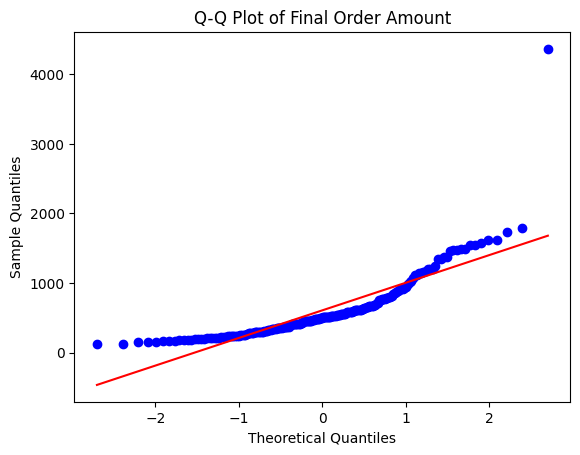

In [3]:
#Quantile Quantile Plot for Normal Distribution
# Step 1: Import the libraries
import matplotlib.pyplot as plt
import scipy.stats as stats

# Step 2: Remove missing values from Final_Amount
order_amount = df["Final_Amount"].dropna()

# Step 3: Create a quantile-quantile plot
stats.probplot(order_amount, dist="norm", plot=plt)

# Step 4: Add a title
plt.title("Q-Q Plot of Final Order Amount")

# Step 5: Label the axes
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")

# Step 6: Show the plot
plt.show()

City
Bengaluru    32508.0
Delhi        30953.0
Mumbai       28437.0
Pune         15574.5
Hyderabad    13847.0
Name: Final_Amount, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

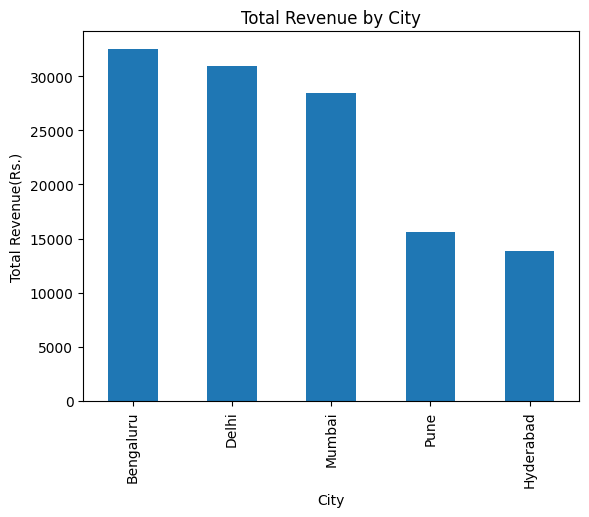

In [7]:
# Bar chart
# Step 1:Find total revenue for each city
city_revenue = df.groupby("City")["Final_Amount"].sum()

# Step 2: Arrange cities from highest to lowest revenue
city_revenue = city_revenue.sort_values(ascending=False)

# Step 3: Print the revenue of each city
print(city_revenue)

# Step 4: Create a bar chart
city_revenue.plot(kind="bar")

# Step 5: Add a title and axis labels
plt.title("Total Revenue by City")
plt.ylabel("Total Revenue(Rs.)")

# Step 6: Show the plot
plt.show

Order_Date
2026-07    51
2026-08    63
2026-09    86
Freq: M, Name: Order_ID, dtype: int64


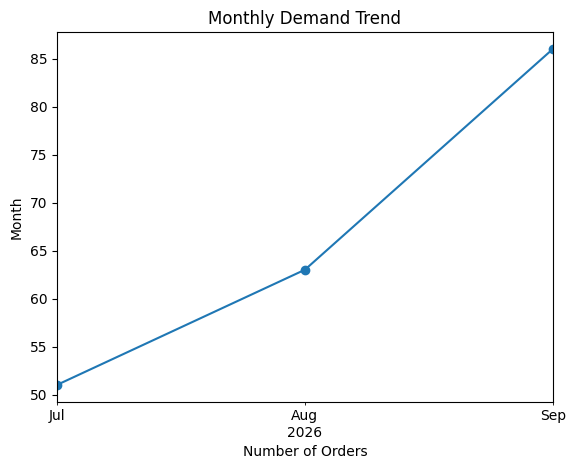

In [8]:
# Step 1: convert Order_Date into a data format
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# Step 2: count the number of order each month
monthly_orders = df.groupby(df["Order_Date"].dt.to_period("M"))["Order_ID"].count()

# Step 3: Print the monthly order
print(monthly_orders)

# Step 4: Create a line chart
monthly_orders.plot(kind="line", marker= "o")

# Step 5: Add a title and axis labels
plt.title("Monthly Demand Trend")
plt.ylabel("Month")
plt.xlabel("Number of Orders")

# Step 6: Show the chart
plt.show()

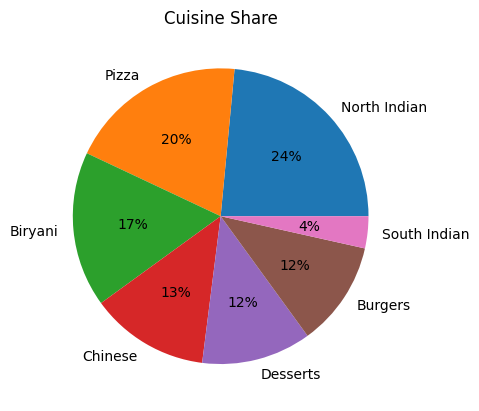

In [10]:
# PIE CHART: Cuisine Share

# Step 1: Count orders for each cuisine
cuisine_counts = df["Cuisine"].value_counts()

# Step 2: Create a pie chart
plt.pie(cuisine_counts.values,
        labels=cuisine_counts.index,
        autopct="%1.0f%%")

# Step 3: Add title
plt.title("Cuisine Share")

# Step 4: Show the chart
plt.show()

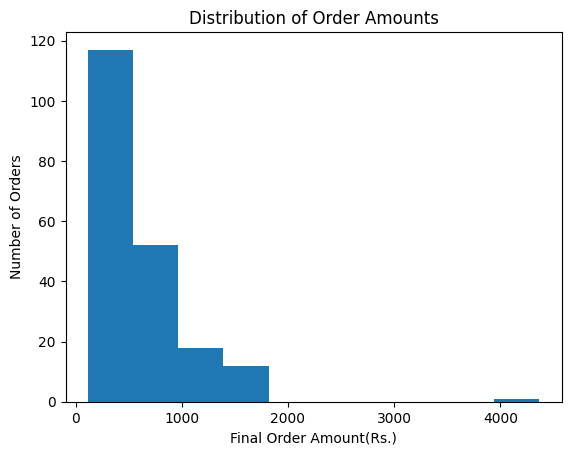

In [9]:
#HISTOGRRAM
# Create histogram of order amounts
plt.hist(df["Final_Amount"].dropna(), bins=10)

# Add title and labels
plt.title("Distribution of Order Amounts")
plt.xlabel("Final Order Amount(Rs.)")
plt.ylabel("Number of Orders")

# Show the plot
plt.show()

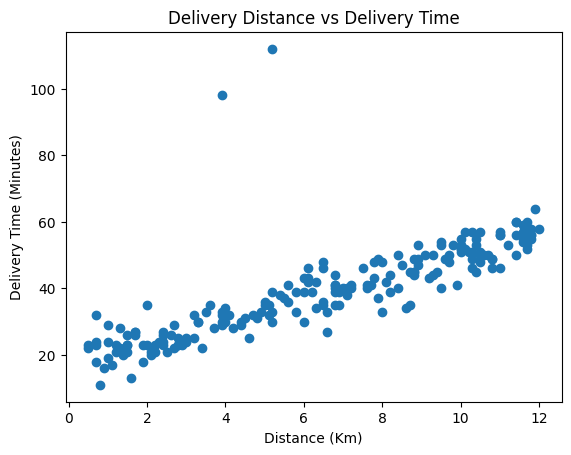

In [11]:
# Scatter plot
# Create scatter plot
plt.scatter(df["Distance_Km"], df["Delivery_Time_Min"])

# Add title and labels
plt.title("Delivery Distance vs Delivery Time")
plt.xlabel("Distance (Km)")
plt.ylabel("Delivery Time (Minutes)")

# Show chart
plt.show()

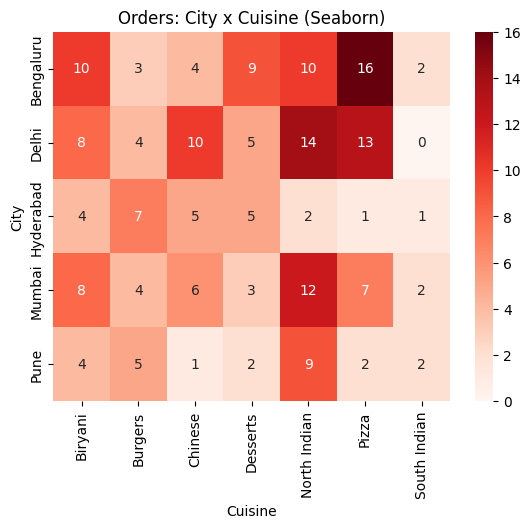

In [12]:
# Heatmap: City x Cuisine order counts (the dark/zero cells show gaps)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the missing city_cuisine variable using a cross-tabulation
city_cuisine = pd.crosstab(df["City"], df["Cuisine"])

sns.heatmap(city_cuisine, annot=True, fmt="d", cmap="Reds")
plt.title("Orders: City x Cuisine (Seaborn)")
plt.show()

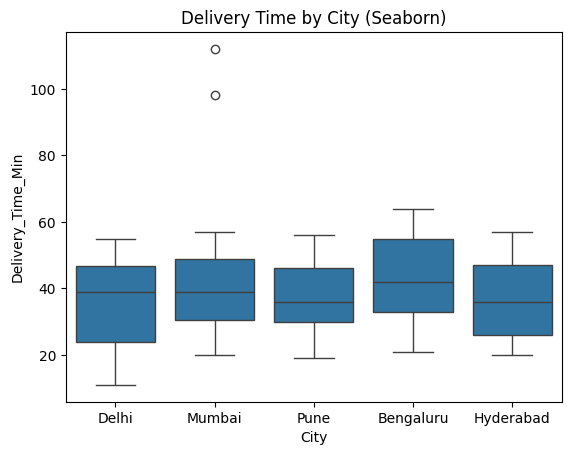

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot
sns.boxplot(data=df, x="City", y="Delivery_Time_Min")
plt.title("Delivery Time by City (Seaborn)")
plt.show()